# Momento evaluativo II: red neuronal convolucional

**Institución Universitaria ITM — Facultad de Ingenierías**
**Materia:** Introducción al aprendizaje profundo
**Docente:** Kevin Osorno Castillo

Clasificación binaria de radiografías óseas: **fracturada** o **no fracturada**, con una CNN diseñada e implementada desde capas básicas de PyTorch.

Restricciones de la actividad respetadas en este notebook:

- No hay transfer learning ni modelos preentrenados.
- No se importa ninguna arquitectura completa (ResNet, VGG, AlexNet, etc.).
- No se aplica data augmentation. Solo cambio de tamaño, conversión a tensor y normalización.

## 1. Selección del conjunto de datos

| Dato | Valor |
| --- | --- |
| Nombre | Fracture Multi-Region X-ray Data (carpeta `Bone_Fracture_Binary_Classification`) |
| Fuente | Kaggle, autora B. Madushani Rodrigo |
| Enlace | https://www.kaggle.com/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data |
| Licencia | Open Data Commons Attribution License (ODC-By) v1.0 |
| Problema | Clasificación de imágenes |
| Clases | 2: `fractured` y `not fractured` |

**¿Por qué una CNN?** Una radiografía es una imagen: la señal útil (línea de fractura, interrupción de la cortical, cambio local de intensidad) ocupa una región pequeña y puede aparecer en distintas posiciones del hueso. Una convolución recorre la imagen con el mismo filtro, así que detecta ese patrón local sin importar en qué píxel exacto esté. Las capas siguientes combinan esos bordes en texturas y, más adelante, en una decisión de clase. Una capa densa sobre todos los píxeles no tiene ese sesgo espacial y dispara el número de parámetros.

In [1]:
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".mplconfig"))

import kagglehub

dataset_path = Path(kagglehub.dataset_download("bmadushanirodrigo/fracture-multi-region-x-ray-data"))
DATA_DIR = dataset_path / "Bone_Fracture_Binary_Classification" / "Bone_Fracture_Binary_Classification"
print("Ruta del dataset:", DATA_DIR)
print("Divisiones publicadas:", sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()))

Ruta del dataset: /home/xxx/.cache/kagglehub/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/versions/2/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification
Divisiones publicadas: ['test', 'train', 'val']


In [2]:
from collections import Counter
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

EXTENSIONES = {".jpg", ".jpeg", ".png"}
CLASES_DIR = ["fractured", "not fractured"]
DIVISIONES = ["train", "val", "test"]


def listar_imagenes(division, clase):
    carpeta = DATA_DIR / division / clase
    return sorted(p for p in carpeta.iterdir() if p.suffix.lower() in EXTENSIONES)


conteos = {}
total = 0
for division in DIVISIONES:
    conteos[division] = {}
    for clase in CLASES_DIR:
        n = len(listar_imagenes(division, clase))
        conteos[division][clase] = n
        total += n

print(f"Número total de imágenes: {total}")
print(f"Número de clases: {len(CLASES_DIR)}")
print()
for division in DIVISIONES:
    subtotal = sum(conteos[division].values())
    print(f"{division:5}  {subtotal:5} imágenes  ({100 * subtotal / total:.2f}%)")
    for clase in CLASES_DIR:
        print(f"         {clase:14} {conteos[division][clase]:5}")

modos = Counter()
tamanos = Counter()
muestra = 0
for division in DIVISIONES:
    for clase in CLASES_DIR:
        for ruta in listar_imagenes(division, clase):
            with Image.open(ruta) as imagen:
                modos[imagen.mode] += 1
                tamanos[imagen.size] += 1
            muestra += 1

print()
print("Modos de color:", dict(modos))
print("Tamaños distintos:", len(tamanos))
print("Tamaños más frecuentes:")
for tamano, n in tamanos.most_common(5):
    print(f"  {tamano[0]} x {tamano[1]} px : {n} imágenes")

Número total de imágenes: 10581
Número de clases: 2

train   9246 imágenes  (87.38%)
         fractured       4606
         not fractured   4640
val      829 imágenes  (7.83%)
         fractured        337
         not fractured    492
test     506 imágenes  (4.78%)
         fractured        238
         not fractured    268



Modos de color: {'L': 511, 'RGB': 10041, 'P': 9, 'RGBA': 20}
Tamaños distintos: 431
Tamaños más frecuentes:
  224 x 224 px : 9512 imágenes
  373 x 454 px : 110 imágenes
  2304 x 2880 px : 94 imágenes
  100 x 100 px : 31 imágenes
  454 x 373 px : 25 imágenes


Las imágenes no comparten un único tamaño original: la mayoría mide 224×224 px y está en RGB, pero hay radiografías más grandes y unos pocos archivos en escala de grises o paleta. Por eso, antes de la red, todas se convierten a RGB y se redimensionan al mismo alto y ancho.

El conjunto ya trae las carpetas `train`, `val` y `test`. Se respeta esa división. Varios archivos son copias rotadas de una misma radiografía (el nombre incluye `rotated`). Si se mezclaran todas las imágenes y se volviera a sortear el reparto, copias de la misma radiografía podrían caer en entrenamiento y en prueba a la vez, y la accuracy dejaría de medir generalización. Las proporciones de la división oficial quedan calculadas en la celda anterior.

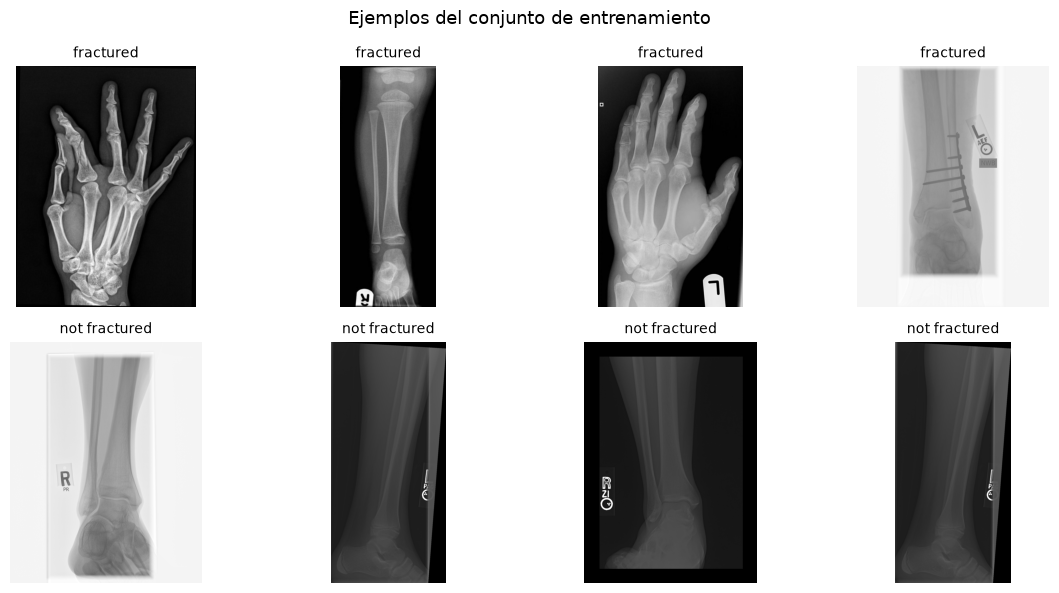

In [3]:
import matplotlib.pyplot as plt
import numpy as np

fig, ejes = plt.subplots(2, 4, figsize=(12, 6))
for fila, clase in enumerate(CLASES_DIR):
    ejemplos = listar_imagenes("train", clase)[:4]
    for col, ruta in enumerate(ejemplos):
        with Image.open(ruta) as imagen:
            ejes[fila, col].imshow(imagen.convert("RGB"))
        ejes[fila, col].set_title(clase, fontsize=10)
        ejes[fila, col].axis("off")
fig.suptitle("Ejemplos del conjunto de entrenamiento", fontsize=13)
fig.tight_layout()
plt.show()

## 2. Preparación de los datos

Proporción usada, tomada de la división oficial del dataset (se confirma con los conteos de la sección 1):

- Entrenamiento: carpeta `train`.
- Validación: carpeta `val`.
- Prueba: carpeta `test`.

La carpeta de prueba no se usa para elegir arquitectura, épocas ni learning rate. Solo se evalúa al final.

Transformaciones permitidas, y las únicas que se aplican:

1. Conversión a RGB, para que toda imagen tenga 3 canales.
2. Cambio de tamaño a 128×128.
3. Conversión a tensor con valores en `[0, 1]`.
4. Normalización por canal con media 0.5 y desviación 0.5, de modo que la entrada quede aproximadamente en `[-1, 1]`.

No hay rotaciones, recortes aleatorios, volteos ni cambios de brillo.

El tensor que entra a la red tiene forma **`[B, C, H, W]`**:

- `B`: tamaño del lote (batch size), aquí 32.
- `C`: canales. 3, porque la imagen se trata como RGB.
- `H`: alto, 128 píxeles.
- `W`: ancho, 128 píxeles.

En cada paso de entrenamiento el tensor es `[32, 3, 128, 128]`.

In [4]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEMILLA = 42
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

TAMANO = 128
BATCH_SIZE = 32

transformacion = transforms.Compose([
    transforms.Resize((TAMANO, TAMANO)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

conjuntos = {
    division: datasets.ImageFolder(DATA_DIR / division, transform=transformacion)
    for division in DIVISIONES
}

cargadores = {
    "train": DataLoader(conjuntos["train"], batch_size=BATCH_SIZE, shuffle=True, num_workers=0),
    "val": DataLoader(conjuntos["val"], batch_size=BATCH_SIZE, shuffle=False, num_workers=0),
    "test": DataLoader(conjuntos["test"], batch_size=BATCH_SIZE, shuffle=False, num_workers=0),
}

NOMBRES_CLASE = conjuntos["train"].classes
print("Índice -> clase:", {i: nombre for i, nombre in enumerate(NOMBRES_CLASE)})
for division, conjunto in conjuntos.items():
    print(f"{division:5} {len(conjunto):5} imágenes")

imagenes, etiquetas = next(iter(cargadores["train"]))
print("Tensor de un lote:", tuple(imagenes.shape), imagenes.dtype)
print("Rango después de normalizar: "
      f"[{imagenes.min().item():.3f}, {imagenes.max().item():.3f}]")
print("[B, C, H, W] = "
      f"[{imagenes.shape[0]}, {imagenes.shape[1]}, {imagenes.shape[2]}, {imagenes.shape[3]}]")

Índice -> clase: {0: 'fractured', 1: 'not fractured'}
train  9246 imágenes
val     829 imágenes
test    506 imágenes


Tensor de un lote: (32, 3, 128, 128) torch.float32
Rango después de normalizar: [-1.000, 0.961]
[B, C, H, W] = [32, 3, 128, 128]


## 3. Diseño de la arquitectura

La red es propia. Tiene tres convoluciones, ReLU después de cada convolución y de la capa oculta densa, tres max-pooling y dos capas lineales para clasificar.

Cada convolución usa kernel 3×3, stride 1 y padding 1. El padding conserva el alto y el ancho; el pooling 2×2 con stride 2 los reduce a la mitad. Partiendo de 128, las mapas quedan en 64, 32 y 16.

| Capa | Configuración | Dimensión de salida |
| --- | --- | --- |
| Entrada | Imagen RGB | `[B, 3, 128, 128]` |
| Conv1 | 16 filtros, kernel 3×3, stride 1, padding 1, ReLU | `[B, 16, 128, 128]` |
| Pool1 | MaxPool kernel 2×2, stride 2 | `[B, 16, 64, 64]` |
| Conv2 | 32 filtros, kernel 3×3, stride 1, padding 1, ReLU | `[B, 32, 64, 64]` |
| Pool2 | MaxPool kernel 2×2, stride 2 | `[B, 32, 32, 32]` |
| Conv3 | 64 filtros, kernel 3×3, stride 1, padding 1, ReLU | `[B, 64, 32, 32]` |
| Pool3 | MaxPool kernel 2×2, stride 2 | `[B, 64, 16, 16]` |
| Flatten | Vectoriza los mapas | `[B, 16384]` |
| FC1 | 16384 → 64 neuronas, ReLU | `[B, 64]` |
| Salida | 64 → 2 neuronas (sin activación; la aplica la pérdida) | `[B, 2]` |

La salida son dos logits, uno por clase. `CrossEntropyLoss` aplica log-softmax internamente, por eso la última capa no lleva Softmax.

In [5]:
import torch.nn as nn


class CNNFracturas(nn.Module):
    """CNN propia para clasificar radiografías en fracturada / no fracturada."""

    def __init__(self, num_clases=2):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.relu = nn.ReLU()
        self.aplanar = nn.Flatten()
        self.fc1 = nn.Linear(64 * 16 * 16, 64)
        self.fc2 = nn.Linear(64, num_clases)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.relu(self.fc1(self.aplanar(x)))
        return self.fc2(x)


dispositivo = torch.device("cpu")
modelo = CNNFracturas(num_clases=len(NOMBRES_CLASE)).to(dispositivo)
print(modelo)
print()
print("Parámetros entrenables:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))

modelo.eval()
with torch.no_grad():
    sonda = torch.zeros(1, 3, TAMANO, TAMANO, device=dispositivo)
    x = sonda
    print(f"{'Entrada':8} {tuple(x.shape)}")
    x = modelo.relu(modelo.conv1(x)); print(f"{'Conv1':8} {tuple(x.shape)}")
    x = modelo.pool(x);               print(f"{'Pool1':8} {tuple(x.shape)}")
    x = modelo.relu(modelo.conv2(x)); print(f"{'Conv2':8} {tuple(x.shape)}")
    x = modelo.pool(x);               print(f"{'Pool2':8} {tuple(x.shape)}")
    x = modelo.relu(modelo.conv3(x)); print(f"{'Conv3':8} {tuple(x.shape)}")
    x = modelo.pool(x);               print(f"{'Pool3':8} {tuple(x.shape)}")
    x = modelo.aplanar(x);            print(f"{'Flatten':8} {tuple(x.shape)}")
    x = modelo.relu(modelo.fc1(x));   print(f"{'FC1':8} {tuple(x.shape)}")
    x = modelo.fc2(x);                print(f"{'Salida':8} {tuple(x.shape)}")

CNNFracturas(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (aplanar): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=16384, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)

Parámetros entrenables: 1072354
Entrada  (1, 3, 128, 128)
Conv1    (1, 16, 128, 128)
Pool1    (1, 16, 64, 64)
Conv2    (1, 32, 64, 64)
Pool2    (1, 32, 32, 32)
Conv3    (1, 64, 32, 32)
Pool3    (1, 64, 16, 16)
Flatten  (1, 16384)
FC1      (1, 64)
Salida   (1, 2)


## 4. Entrenamiento

| Hiperparámetro | Valor | Motivo |
| --- | --- | --- |
| Función de pérdida | `CrossEntropyLoss` | Clasificación con dos clases mutuamente excluyentes |
| Optimizador | Adam | Ajusta el paso por parámetro y suele converger bien en CNN pequeñas |
| Learning rate | 0.001 | Valor inicial habitual de Adam para este tamaño de red |
| Batch size | 32 | Compromiso entre estabilidad del gradiente y memoria en CPU |
| Épocas | 12 | Suficiente para ver si la validación se separa del entrenamiento |

En cada época se registran loss y accuracy de entrenamiento y de validación. Accuracy es la fracción de imágenes cuya clase predicha (argmax del logit) coincide con la etiqueta.

In [6]:
import torch.nn.functional as F
from tqdm.auto import tqdm

FUNCION_PERDIDA = nn.CrossEntropyLoss()
OPTIMIZADOR = torch.optim.Adam(modelo.parameters(), lr=1e-3)
EPOCAS = 12

historial = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}


def evaluar(cargador):
    modelo.eval()
    perdida_total = 0.0
    correctas = 0
    vistas = 0
    with torch.no_grad():
        for imagenes, etiquetas in cargador:
            imagenes = imagenes.to(dispositivo)
            etiquetas = etiquetas.to(dispositivo)
            logits = modelo(imagenes)
            perdida_total += FUNCION_PERDIDA(logits, etiquetas).item() * etiquetas.size(0)
            correctas += (logits.argmax(dim=1) == etiquetas).sum().item()
            vistas += etiquetas.size(0)
    return perdida_total / vistas, correctas / vistas


def entrenar_una_epoca(cargador):
    modelo.train()
    perdida_total = 0.0
    correctas = 0
    vistas = 0
    for imagenes, etiquetas in tqdm(cargador, leave=False):
        imagenes = imagenes.to(dispositivo)
        etiquetas = etiquetas.to(dispositivo)
        OPTIMIZADOR.zero_grad()
        logits = modelo(imagenes)
        perdida = FUNCION_PERDIDA(logits, etiquetas)
        perdida.backward()
        OPTIMIZADOR.step()
        perdida_total += perdida.item() * etiquetas.size(0)
        correctas += (logits.argmax(dim=1) == etiquetas).sum().item()
        vistas += etiquetas.size(0)
    return perdida_total / vistas, correctas / vistas


for epoca in range(1, EPOCAS + 1):
    train_loss, train_acc = entrenar_una_epoca(cargadores["train"])
    val_loss, val_acc = evaluar(cargadores["val"])
    historial["train_loss"].append(train_loss)
    historial["train_acc"].append(train_acc)
    historial["val_loss"].append(val_loss)
    historial["val_acc"].append(val_acc)
    print(
        f"Época {epoca:02d}/{EPOCAS}  "
        f"train loss {train_loss:.4f}  acc {train_acc:.4f}  |  "
        f"val loss {val_loss:.4f}  acc {val_acc:.4f}"
    )

ruta_pesos = Path("modelo_cnn_fracturas.pt")
torch.save(
    {"estado": modelo.state_dict(), "clases": NOMBRES_CLASE, "tamano": TAMANO},
    ruta_pesos,
)
print("Pesos guardados en", ruta_pesos.resolve())

  0%|          | 0/289 [00:00<?, ?it/s]

/home/xxx/Documentos/deeplearning/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Época 01/12  train loss 0.3949  acc 0.8051  |  val loss 0.3265  acc 0.8794


  0%|          | 0/289 [00:00<?, ?it/s]

Época 02/12  train loss 0.0899  acc 0.9713  |  val loss 0.1717  acc 0.9433


...

Época 10/12  train loss 0.0000  acc 1.0000  |  val loss 0.0759  acc 0.9843


  0%|          | 0/289 [00:00<?, ?it/s]

Época 11/12  train loss 0.0000  acc 1.0000  |  val loss 0.0790  acc 0.9831


  0%|          | 0/289 [00:00<?, ?it/s]

Época 12/12  train loss 0.0000  acc 1.0000  |  val loss 0.0857  acc 0.9831
Pesos guardados en /home/xxx/Documentos/deeplearning/modelo_cnn_fracturas.pt


## 5. Análisis del entrenamiento

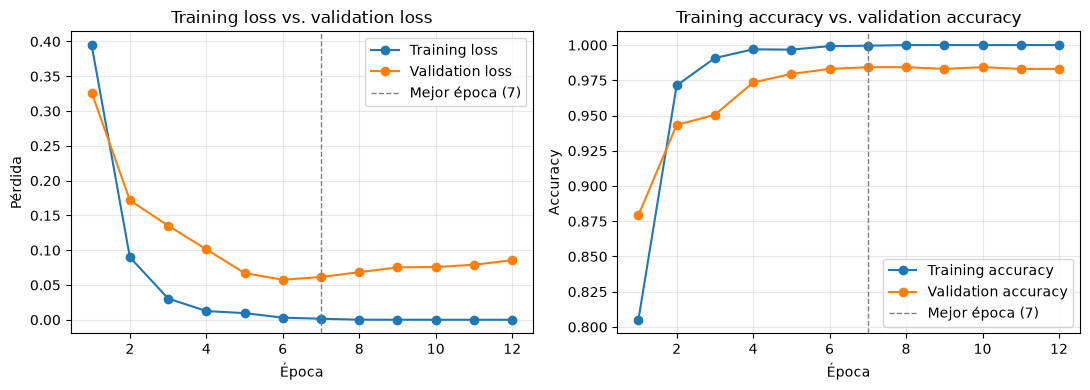

Mejor época según accuracy de validación: 7
  val accuracy = 0.9843
  val loss     = 0.0615
  train accuracy en esa época = 0.9996
  train loss en esa época     = 0.0015


In [7]:
epocas = np.arange(1, EPOCAS + 1)
mejor = int(np.argmax(historial["val_acc"]))
if any(historial["val_acc"][i] == historial["val_acc"][mejor] and historial["val_loss"][i] < historial["val_loss"][mejor]
       for i in range(EPOCAS)):
    empatadas = [i for i in range(EPOCAS) if historial["val_acc"][i] == historial["val_acc"][mejor]]
    mejor = min(empatadas, key=lambda i: historial["val_loss"][i])

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(epocas, historial["train_loss"], marker="o", label="Training loss")
ejes[0].plot(epocas, historial["val_loss"], marker="o", label="Validation loss")
ejes[0].axvline(mejor + 1, color="gray", linestyle="--", linewidth=1, label=f"Mejor época ({mejor + 1})")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida")
ejes[0].set_title("Training loss vs. validation loss")
ejes[0].legend()
ejes[0].grid(alpha=0.3)

ejes[1].plot(epocas, historial["train_acc"], marker="o", label="Training accuracy")
ejes[1].plot(epocas, historial["val_acc"], marker="o", label="Validation accuracy")
ejes[1].axvline(mejor + 1, color="gray", linestyle="--", linewidth=1, label=f"Mejor época ({mejor + 1})")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Accuracy")
ejes[1].set_title("Training accuracy vs. validation accuracy")
ejes[1].legend()
ejes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(f"Mejor época según accuracy de validación: {mejor + 1}")
print(f"  val accuracy = {historial['val_acc'][mejor]:.4f}")
print(f"  val loss     = {historial['val_loss'][mejor]:.4f}")
print(f"  train accuracy en esa época = {historial['train_acc'][mejor]:.4f}")
print(f"  train loss en esa época     = {historial['train_loss'][mejor]:.4f}")

In [8]:
from IPython.display import Markdown, display

ultima = EPOCAS - 1
epoca_mejor_acc = mejor + 1
epoca_min_perdida = int(np.argmin(historial["val_loss"])) + 1
empatadas = [i + 1 for i in range(EPOCAS) if historial["val_acc"][i] == historial["val_acc"][mejor]]
empatadas_txt = ", ".join(str(e) for e in empatadas)

diferencia = (
    f"En entrenamiento la accuracy pasa de {historial['train_acc'][0]:.1%} a "
    f"{historial['train_acc'][ultima]:.1%} y la pérdida de {historial['train_loss'][0]:.4f} a "
    f"{historial['train_loss'][ultima]:.4f}. "
    f"En validación la accuracy pasa de {historial['val_acc'][0]:.1%} a un máximo de "
    f"{historial['val_acc'][mejor]:.1%} en la época {epoca_mejor_acc}, y cierra en "
    f"{historial['val_acc'][ultima]:.1%}. "
    f"La pérdida de validación es mínima en la época {epoca_min_perdida} "
    f"({historial['val_loss'][epoca_min_perdida - 1]:.4f}) y en la época {EPOCAS} vale "
    f"{historial['val_loss'][ultima]:.4f}. "
    "Después de ese mínimo la pérdida de entrenamiento sigue bajando y la de validación sube. "
    "Es un sobreajuste leve: el modelo memoriza el conjunto de entrenamiento. "
    "La accuracy de validación casi no cae porque casi todas las radiografías ya estaban bien "
    "clasificadas; la pérdida sí crece cuando el modelo se vuelve más seguro en los pocos errores."
)

mejora = (
    f"Guardaría los pesos de la época {epoca_mejor_acc}, que es la de mejor accuracy de validación, "
    f"y detendría ahí el entrenamiento. El archivo `modelo_cnn_fracturas.pt` corresponde a la época "
    f"{EPOCAS}, ya pasado ese punto. "
    "En otro intento bajaría las 64 neuronas de la capa densa o les pondría dropout: esa capa "
    "concentra casi todos los parámetros y es la que más fácil memoriza. "
    "También usaría un scheduler que reduzca el learning rate cuando la pérdida de validación "
    "deje de bajar. Mantendría las tres convoluciones y no usaría data augmentation ni pesos preentrenados."
)

texto = f"""
### Respuestas

**1. ¿En qué época el modelo se comporta mejor sobre datos que no vio al actualizar los pesos?**

En la época **{epoca_mejor_acc}**, con accuracy de validación **{historial['val_acc'][mejor]:.2%}** y pérdida de validación **{historial['val_loss'][mejor]:.4f}**. Esas imágenes no entran al `backward`. Las épocas {empatadas_txt} empatan en accuracy; se elige la {epoca_mejor_acc} por tener la menor pérdida de validación entre ellas. Si el criterio fuera solo la pérdida de validación, la mejor época sería la **{epoca_min_perdida}** ({historial['val_loss'][epoca_min_perdida - 1]:.4f}), con accuracy {historial['val_acc'][epoca_min_perdida - 1]:.2%}.

**2. ¿Qué diferencias hay entre entrenamiento y validación?**

{diferencia}

**3. ¿Qué modificaría para intentar mejorar el modelo?**

{mejora}
"""
display(Markdown(texto))



### Respuestas

**1. ¿En qué época el modelo se comporta mejor sobre datos que no vio al actualizar los pesos?**

En la época **7**, con accuracy de validación **98.43%** y pérdida de validación **0.0615**. Esas imágenes no entran al `backward`. Las épocas 7, 8, 10 empatan en accuracy; se elige la 7 por tener la menor pérdida de validación entre ellas. Si el criterio fuera solo la pérdida de validación, la mejor época sería la **6** (0.0575), con accuracy 98.31%.

**2. ¿Qué diferencias hay entre entrenamiento y validación?**

En entrenamiento la accuracy pasa de 80.5% a 100.0% y la pérdida de 0.3949 a 0.0000. En validación la accuracy pasa de 87.9% a un máximo de 98.4% en la época 7, y cierra en 98.3%. La pérdida de validación es mínima en la época 6 (0.0575) y en la época 12 vale 0.0857. Después de ese mínimo la pérdida de entrenamiento sigue bajando y la de validación sube. Es un sobreajuste leve: el modelo memoriza el conjunto de entrenamiento. La accuracy de validación casi no cae porque casi todas las radiografías ya estaban bien clasificadas; la pérdida sí crece cuando el modelo se vuelve más seguro en los pocos errores.

**3. ¿Qué modificaría para intentar mejorar el modelo?**

Guardaría los pesos de la época 7, que es la de mejor accuracy de validación, y detendría ahí el entrenamiento. El archivo `modelo_cnn_fracturas.pt` corresponde a la época 12, ya pasado ese punto. En otro intento bajaría las 64 neuronas de la capa densa o les pondría dropout: esa capa concentra casi todos los parámetros y es la que más fácil memoriza. También usaría un scheduler que reduzca el learning rate cuando la pérdida de validación deje de bajar. Mantendría las tres convoluciones y no usaría data augmentation ni pesos preentrenados.


## 6. Evaluación sobre el conjunto de prueba

El conjunto de prueba se abre solo después de fijar la arquitectura, la pérdida, el optimizador, el learning rate, el batch size y el número de épocas. No se reentrena con estas imágenes.

Métricas:

- **Accuracy:** proporción de aciertos.
- **Precisión:** de las imágenes predichas como una clase, cuántas lo son.
- **Recall (sensibilidad):** de las imágenes que realmente son de esa clase, cuántas se detectan.
- **F1:** media armónica de precisión y recall.
- **Especificidad de la clase fracturada:** proporción de radiografías no fracturadas que el modelo deja correctamente como no fracturadas.
- **Matriz de confusión.**

               precision    recall  f1-score   support

    fractured     1.0000    0.9832    0.9915       238
not fractured     0.9853    1.0000    0.9926       268

     accuracy                         0.9921       506
    macro avg     0.9926    0.9916    0.9921       506
 weighted avg     0.9922    0.9921    0.9921       506

Accuracy de prueba: 0.9921
Matriz de confusión (filas = real, columnas = predicho):
[[234   4]
 [  0 268]]
Verdaderos positivos (fractura detectada): 234
Falsos negativos (fractura no detectada): 4
Falsos positivos (sana marcada como fractura): 0
Verdaderos negativos: 268
Especificidad respecto a 'not fractured': 1.0000


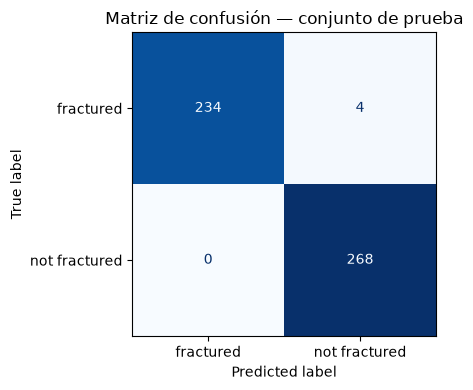

In [9]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

modelo.eval()
y_real = []
y_pred = []
imagenes_test = []
with torch.no_grad():
    for imagenes, etiquetas in cargadores["test"]:
        logits = modelo(imagenes.to(dispositivo))
        y_pred.extend(logits.argmax(dim=1).cpu().tolist())
        y_real.extend(etiquetas.tolist())
        imagenes_test.append(imagenes.cpu())

y_real = np.array(y_real)
y_pred = np.array(y_pred)
imagenes_test = torch.cat(imagenes_test)

print(classification_report(y_real, y_pred, target_names=NOMBRES_CLASE, digits=4))
print(f"Accuracy de prueba: {accuracy_score(y_real, y_pred):.4f}")

matriz = confusion_matrix(y_real, y_pred)
print("Matriz de confusión (filas = real, columnas = predicho):")
print(matriz)

indice_fractura = NOMBRES_CLASE.index("fractured")
indice_sana = NOMBRES_CLASE.index("not fractured")
vn = matriz[indice_sana, indice_sana]
fp = matriz[indice_sana, indice_fractura]
fn = matriz[indice_fractura, indice_sana]
vp = matriz[indice_fractura, indice_fractura]
especificidad = vn / (vn + fp)
print(f"Verdaderos positivos (fractura detectada): {vp}")
print(f"Falsos negativos (fractura no detectada): {fn}")
print(f"Falsos positivos (sana marcada como fractura): {fp}")
print(f"Verdaderos negativos: {vn}")
print(f"Especificidad respecto a 'not fractured': {especificidad:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(matriz, display_labels=NOMBRES_CLASE).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión — conjunto de prueba")
fig.tight_layout()
plt.show()

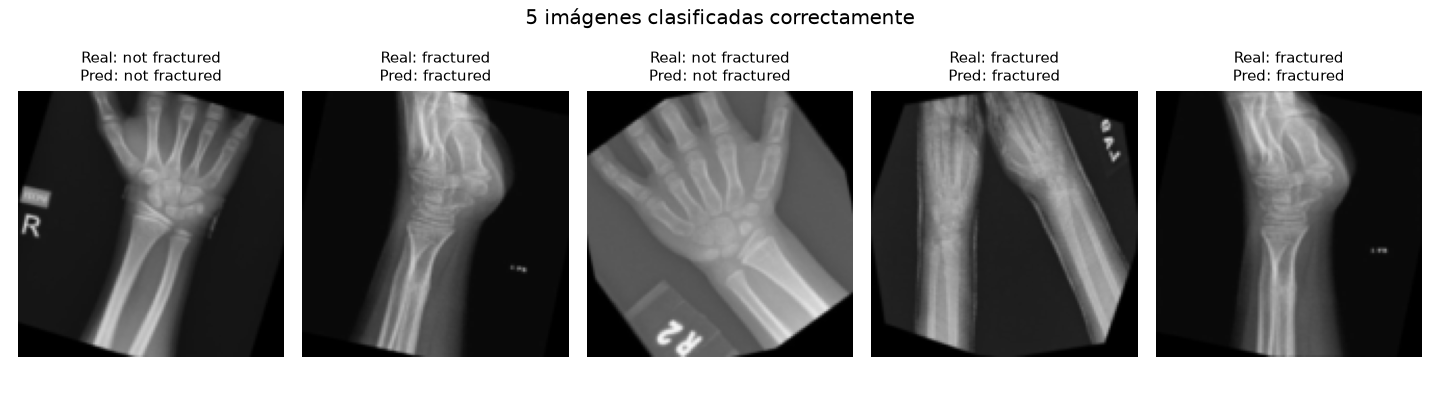

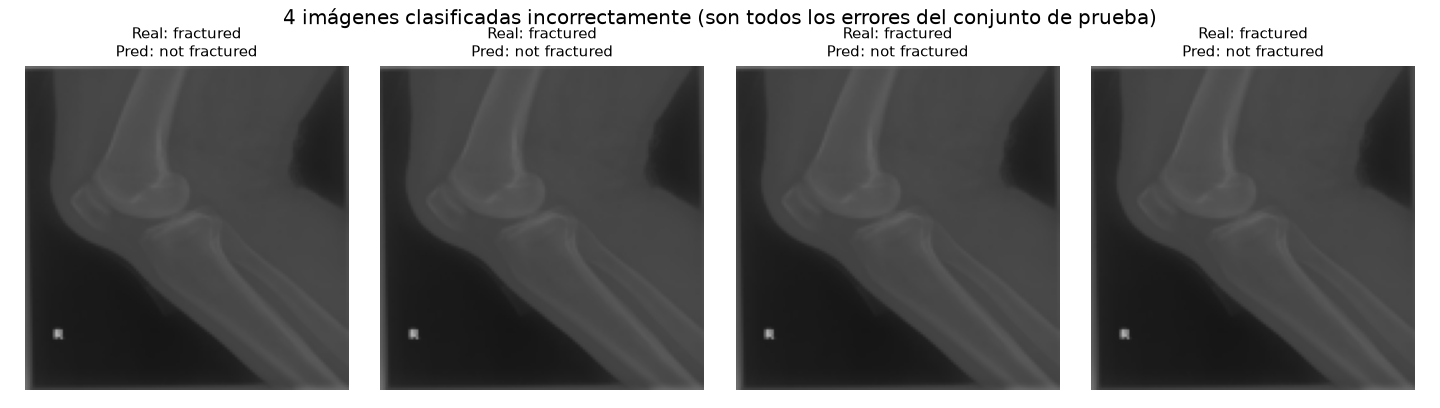

### ¿Hay clases que el modelo tiende a confundir?

El problema solo tiene dos clases, así que toda la confusión es entre ellas. En prueba hay 4 errores, así que la figura muestra todos y no una muestra de cinco.

Sí. La confusión dominante va de **fractured** hacia **not fractured**: 4 fracturas quedan como no fracturadas y 0 radiografías sanas quedan como fractura. En un apoyo al diagnóstico, el falso negativo es el error más costoso, porque una fractura pasaría desapercibida. Visualmente las dos clases comparten hueso, fondo oscuro y bordes intensos; la fractura es a menudo una discontinuidad fina, fácil de confundir con el contorno normal o con el borde de la imagen.

La accuracy de prueba es alta para una CNN de este tamaño. El dataset publicado ya trae muchas copias rotadas de las mismas radiografías, y el reparto oficial no aísla cada radiografía de sus rotaciones. Los cuatro errores de prueba son rotaciones de una misma radiografía de rodilla: el modelo no detecta esa fractura en ninguna de esas orientaciones. Parte del acierto en el resto de las imágenes puede venir de reconocer repeticiones, no solo el trazo de la fractura.

In [10]:
def desnormalizar(tensor):
    imagen = tensor.permute(1, 2, 0).numpy()
    imagen = imagen * 0.5 + 0.5
    return np.clip(imagen, 0, 1)


correctas = np.where(y_real == y_pred)[0]
incorrectas = np.where(y_real != y_pred)[0]
rng = np.random.default_rng(SEMILLA)
elegidas_ok = rng.choice(correctas, size=min(5, len(correctas)), replace=False)
elegidas_mal = rng.choice(incorrectas, size=min(5, len(incorrectas)), replace=False)


def mostrar(indices, titulo):
    fig, ejes = plt.subplots(1, len(indices), figsize=(12, 3))
    if len(indices) == 1:
        ejes = [ejes]
    for ax, indice in zip(ejes, indices):
        ax.imshow(desnormalizar(imagenes_test[indice]))
        ax.set_title(
            f"Real: {NOMBRES_CLASE[y_real[indice]]}\nPred: {NOMBRES_CLASE[y_pred[indice]]}",
            fontsize=9,
        )
        ax.axis("off")
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()


mostrar(elegidas_ok, f"{len(elegidas_ok)} imágenes clasificadas correctamente")
if len(elegidas_mal) < 5:
    titulo_mal = f"{len(elegidas_mal)} imágenes clasificadas incorrectamente (son todos los errores del conjunto de prueba)"
else:
    titulo_mal = "Cinco imágenes clasificadas incorrectamente"
mostrar(elegidas_mal, titulo_mal)

if fn >= fp:
    confusion_txt = (
        f"Sí. La confusión dominante va de **fractured** hacia **not fractured**: "
        f"{fn} fracturas quedan como no fracturadas y {fp} radiografías sanas quedan como fractura. "
        "En un apoyo al diagnóstico, el falso negativo es el error más costoso, porque una fractura "
        "pasaría desapercibida. Visualmente las dos clases comparten hueso, fondo oscuro y bordes "
        "intensos; la fractura es a menudo una discontinuidad fina, fácil de confundir con el contorno "
        "normal o con el borde de la imagen."
    )
else:
    confusion_txt = (
        f"Sí. La confusión dominante va de **not fractured** hacia **fractured**: "
        f"{fp} radiografías sanas se marcan como fractura y {fn} fracturas se marcan como sanas. "
        "El modelo está usando algún borde o cambio de intensidad que también aparece en huesos intactos "
        "(superposición de estructuras, artefacto de la radiografía o el límite del hueso)."
    )

display(Markdown(
    "### ¿Hay clases que el modelo tiende a confundir?\n\n"
    "El problema solo tiene dos clases, así que toda la confusión es entre ellas. "
    f"En prueba hay {len(incorrectas)} errores"
    + (", así que la figura muestra todos y no una muestra de cinco." if len(incorrectas) < 5 else ".")
    + "\n\n"
    + confusion_txt
    + "\n\nLa accuracy de prueba es alta para una CNN de este tamaño. "
    "El dataset publicado ya trae muchas copias rotadas de las mismas radiografías, "
    "y el reparto oficial no aísla cada radiografía de sus rotaciones. "
    "Los cuatro errores de prueba son rotaciones de una misma radiografía de rodilla: el modelo no detecta esa fractura en ninguna de esas orientaciones. Parte del acierto en el resto de las imágenes puede venir de reconocer repeticiones, no solo el trazo de la fractura."
))

## 7. Preguntas de análisis

Las respuestas usan esta arquitectura y los resultados de las secciones anteriores.

### Pregunta 1. ¿Qué características se espera que aprenda cada bloque convolucional?

- **Primeras capas (`conv1`, 16 filtros 3×3).** Bordes locales, cambios bruscos de intensidad y fragmentos del contorno del hueso. En una radiografía eso corresponde a la frontera entre hueso y tejido blando y a trazos muy cortos, del tamaño del kernel.
- **Capas intermedias (`conv2`, 32 filtros).** Combinaciones de esos bordes: segmentos de cortical, textura del hueso y pequeñas interrupciones. El campo receptivo ya cubre una vecindad mayor porque hubo un pooling.
- **Capas más profundas (`conv3`, 64 filtros).** Patrones más compuestos: una discontinuidad alineada con la cortical frente a un contorno continuo. No se espera que esta capa “vea” la radiografía completa; se espera que entregue mapas en los que la presencia de una fractura quede separada del fondo. La decisión final la toman las capas densas sobre esos mapas ya resumidos por el último pooling.

### Pregunta 2. ¿Para qué está el pooling en esta red?

Cada `MaxPool2d(kernel=2, stride=2)` se queda con el valor máximo de cada ventana 2×2 y divide a la mitad el alto y el ancho. En esta CNN eso hace tres cosas:

1. Reduce el tamaño de los mapas (128 → 64 → 32 → 16), y con ello el costo de las convoluciones siguientes y el tamaño del vector que entra a la capa de 16384 unidades.
2. Aporta una invarianza local pequeña: si el trazo de la fractura se corre un píxel, el máximo de la ventana suele seguir activo.
3. Obliga a las capas profundas a trabajar con un resumen, no con cada píxel. La ubicación fina se pierde a propósito; se conserva si en esa zona hubo una activación fuerte.

### Pregunta 3. ¿Qué pasaría con el número de parámetros si las convoluciones se reemplazaran por capas densas sobre todos los píxeles?

Una convolución reutiliza el mismo kernel en todas las posiciones. `conv1` tiene `3 × 16 × 3 × 3 + 16 = 448` parámetros, independiente de que la imagen mida 128×128. Una capa densa que viera los `3 × 128 × 128 = 49152` píxeles y produjera un vector del mismo ancho que el flatten actual (16384) necesitaría `49152 × 16384 + 16384` parámetros, del orden de cientos de millones, solo en esa capa. La celda siguiente calcula la cifra exacta y la compara con las tres convoluciones de esta red.

Además del conteo, se perdería el sesgo que hace útil a la CNN en radiografías: detectar el mismo patrón local en cualquier posición del hueso.

In [11]:
parametros = {nombre: p.numel() for nombre, p in modelo.named_parameters()}
conv = sum(v for k, v in parametros.items() if k.startswith("conv"))
densas = sum(v for k, v in parametros.items() if k.startswith("fc"))
print("Parámetros por tensor:")
for nombre, n in parametros.items():
    print(f"  {nombre:20} {n:10}")
print(f"Total convoluciones: {conv}")
print(f"Total capas densas:  {densas}")
print(f"Total de la CNN:     {conv + densas}")

pixeles = 3 * TAMANO * TAMANO
unidades = 64 * 16 * 16
densa_equivalente = pixeles * unidades + unidades
print()
print(f"Píxeles de entrada: {pixeles}")
print(f"Capa densa {pixeles} → {unidades}: {densa_equivalente:,} parámetros")
print(f"Veces más parámetros que las tres convoluciones: {densa_equivalente / conv:.0f}x")

Parámetros por tensor:
  conv1.weight                432
  conv1.bias                   16
  conv2.weight               4608
  conv2.bias                   32
  conv3.weight              18432
  conv3.bias                   64
  fc1.weight              1048576
  fc1.bias                     64
  fc2.weight                  128
  fc2.bias                      2
Total convoluciones: 23584
Total capas densas:  1048770
Total de la CNN:     1072354

Píxeles de entrada: 49152
Capa densa 49152 → 16384: 805,322,752 parámetros
Veces más parámetros que las tres convoluciones: 34147x


## Cierre

El notebook cubre la descripción del dataset, la exploración, el diseño de una CNN propia, el entrenamiento con curvas de pérdida y accuracy, la evaluación en prueba (matriz de confusión y métricas) y el análisis de aciertos, errores y preguntas de la guía.

Los pesos guardados en `modelo_cnn_fracturas.pt` son los de la época 12. La época de mejor accuracy de validación es la 7; si se fuera a usar el modelo, conviene conservar esos pesos y no los de la última época.
